In [3]:
# BLOC 1 — Charger, nettoyer, agréger par catégorie
import pandas as pd

# Lire le fichier (en-tête des colonnes sur la 3e ligne = index 2)
df = pd.read_excel("../data/Value per month per Chain - Product.xlsx", header=2)
# Enlever les lignes vides (bas de tableau, totaux)
df = df.dropna(subset=["Chain - Product"])

# Convertir la date texte en vraie date
df["date"] = pd.to_datetime(df["reference_date"])

# Agréger par catégorie et par mois (la somme règle aussi les doublons de SKU)
cat = (df.groupby(["product_line", "date"])["value"].sum()
         .reset_index()
         .rename(columns={"product_line": "categorie", "value": "ventes"}))

# Vérifications
print("Nombre de lignes après agrégation :", len(cat))
print("\nNombre de mois par catégorie :")
print(cat.groupby("categorie")["date"].nunique())
print("\nAperçu Dog :")
print(cat[cat["categorie"] == "Dog"].head(6).to_string(index=False))

Nombre de lignes après agrégation : 190

Nombre de mois par catégorie :
categorie
Cat           43
Cat Treats    18
Dental        43
Dog           43
Dog Treats    43
Name: date, dtype: int64

Aperçu Dog :
categorie       date    ventes
      Dog 2023-01-31  56504.03
      Dog 2023-02-28  53432.85
      Dog 2023-03-31 101062.96
      Dog 2023-04-30  74147.96
      Dog 2023-05-31  86241.36
      Dog 2023-06-30  85828.71


Train : 31 mois (de 2023-01-31 à 2025-07-31)
Test  : 12 mois  (de 2025-08-31 à 2026-07-31)

>>> MAPE de la baseline saisonnière sur Dog : 25.8%


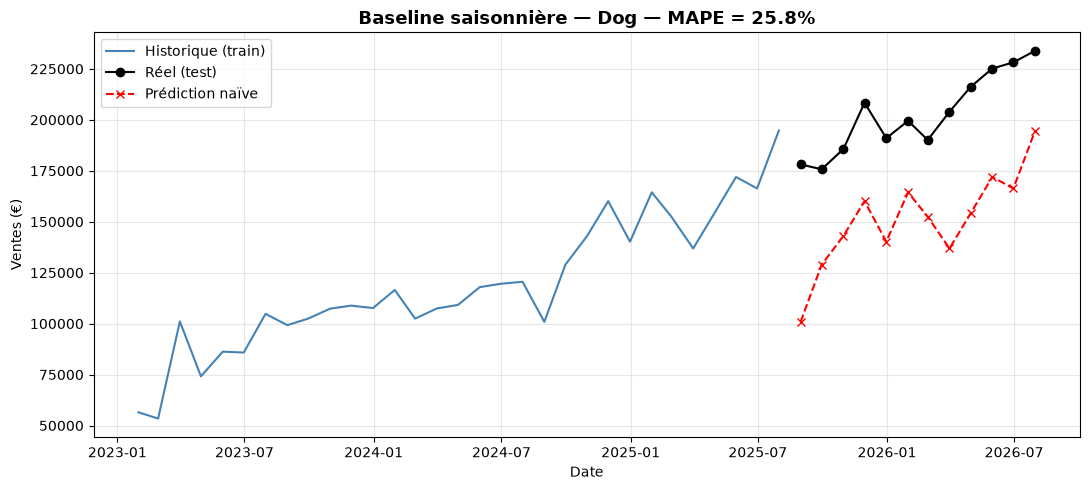

In [ ]:
# BLOC 2 — Baseline saisonnière naïve sur Dog
import numpy as np
import matplotlib.pyplot as plt

# 1) Isoler la série Dog, triée par date
dog = cat[cat["categorie"] == "Dog"].sort_values("date").reset_index(drop=True)

# 2) Découper train / test : les 12 derniers mois en test
n_test = 12
train = dog.iloc[:-n_test].copy()
test  = dog.iloc[-n_test:].copy()

print(f"Train : {len(train)} mois (de {train['date'].min().date()} à {train['date'].max().date()})")
print(f"Test  : {len(test)} mois  (de {test['date'].min().date()} à {test['date'].max().date()})")

# 3) Prédiction naïve : chaque valeur de test = valeur du même mois, 12 mois plus tôt
predictions = []
for date_test in test["date"]:
    date_precedente = date_test - pd.DateOffset(years=1)
    valeur = dog.loc[dog["date"] == date_precedente, "ventes"].values[0]
    predictions.append(valeur)

test["prediction"] = predictions

# 4) Calcul du MAPE (Mean Absolute Percentage Error)
test["erreur_pct"] = np.abs(test["ventes"] - test["prediction"]) / test["ventes"] * 100
mape = test["erreur_pct"].mean()

print(f"\n>>> MAPE de la baseline saisonnière sur Dog : {mape:.1f}%")

# 5) Graphique
plt.figure(figsize=(11, 5))
plt.plot(train["date"], train["ventes"], label="Historique (train)", color="steelblue")
plt.plot(test["date"],  test["ventes"], label="Réel (test)", color="black", marker="o")
plt.plot(test["date"],  test["prediction"], label="Prédiction naïve", color="red", marker="x", linestyle="--")
plt.title(f"Baseline saisonnière — Dog — MAPE = {mape:.1f}%", fontsize=13, fontweight="bold")
plt.xlabel("Date"); plt.ylabel("Ventes (€)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/baseline_dog.png", dpi=110, bbox_inches="tight")
plt.show()